# Results

The three signal controllers compared, from a single baseline setting to one
setting at a time, several settings at once, and the lights and queues over
time:

1. the model running: the three controllers side by side, animated
2. the baseline: the three controllers compared
3. mean wait as each setting changes on its own
4. several settings changed at once
5. the effect of each setting on the adaptive controller's advantage
6. the lights and the cars waiting over time
7. the length of the pockets
8. the same sweeps when blocked cars queue instead of being turned away

**Baseline:** arrival rate 0.15 (average chance that a car arrives on each
approach in a step), north–south probability 0.5 (balanced traffic), left-turn
and right-turn probability 0.2 each, no reaction delay. This is busy but below
what any of the controllers can serve.

The data come from `python -m utils.results_sweeps` (`data/fine_sweeps.csv`,
`data/scenarios.csv`, `data/fine_pockets.csv`) and, for one figure, the main
experiment (`data/sweep_results.csv`). Every setting is run with the same seeds
for all three controllers, so they see exactly the same arriving cars. Waits
are in steps (about one second each). Cars that find the entry full are turned
away; the fraction turned away is shown where it matters, and section 8
repeats the sweeps with such cars kept in a queue instead. Figures are saved to
`figures/` with names starting `results_`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path("../..")                          # project folder (this notebook is in notebooks/Results)
sys.path.insert(0, str(ROOT.resolve()))       # so that src/ and utils/ can be imported
FIGURES = ROOT / "figures"

from src.intersection import Intersection
from utils.metrics import run_and_measure
from utils.results_sweeps import BASELINE

CONTROLLERS = ["fixed", "webster", "adaptive"]
LABELS = {"fixed": "Fixed-time (untuned)", "webster": "Fixed-time (Webster)", "adaptive": "Adaptive"}
COLOURS = {"fixed": "C0", "webster": "C2", "adaptive": "C1"}
# A second colour for each controller, for a second condition shown in the same
# panel (such as reaction delay 0.2, or blocked cars turned away).
ALT_COLOURS = {"fixed": "C4", "webster": "C5", "adaptive": "C3"}
# code name of each setting -> (column in the data files, axis label)
FACTORS = {
    "demand": ("arrival_rate", "Arrival rate (cars per approach per step)"),
    "ns_probability": ("north_south_probability", "North–south probability"),
    "reaction_delay": ("reaction_delay", "Reaction delay (chance of stalling)"),
    "left_probability": ("left_turn_probability", "Left-turn probability"),
    "right_probability": ("right_turn_probability", "Right-turn probability"),
}


def load(name):
    # One row per run, plus the fraction of arriving cars that were turned away
    # (on average 4 x arrival_rate cars arrive per step, so 400 x arrival_rate per 100 steps).
    df = pd.read_csv(ROOT / "data" / name)
    df["turned_away"] = df["blocked_arrivals"] / (400 * df["arrival_rate"])
    return df


def plot_controllers(ax, runs, by, value="mean_wait", scale=1):
    # One line per controller: the mean of `value` over the seeds for each value of `by`.
    for controller in CONTROLLERS:
        mean = runs[runs["controller"] == controller].groupby(by)[value].mean()
        ax.plot(mean.index, scale * mean, marker="o", markersize=3, color=COLOURS[controller],
                label=LABELS[controller])


def advantage(runs, by, against):
    # Adaptive's percentage reduction in mean wait against another controller,
    # paired run by run (same setting and seed) and averaged over the seeds.
    wide = runs.pivot_table(index=[by, "seed"], columns="controller", values="mean_wait")
    return (100 * (wide[against] - wide["adaptive"]) / wide[against]).groupby(level=0).mean()


def save(fig, name):
    fig.savefig(FIGURES / f"results_{name}.png", dpi=200, bbox_inches="tight")


fine = load("fine_sweeps.csv")
print(f"{len(fine)} runs in the fine sweeps; baseline: {BASELINE}")

2430 runs in the fine sweeps; baseline: {'demand': 0.15, 'ns_probability': 0.5, 'left_probability': 0.2, 'right_probability': 0.2, 'reaction_delay': 0.0}


## 1. The model running: three controllers side by side

Three copies of the intersection at the baseline receive exactly the same
arriving cars; only the signal controller differs:

* **Fixed-time (untuned)**: every phase gets 20 steps of green, always in the
  same order.
* **Fixed-time (Webster)**: the same order, with green times designed by
  Webster's method from the average demand.
* **Adaptive**: after a minimum green of 5 steps, the light changes as soon as
  another phase's waiting cars have waited longer in total.

**How to read the picture.** Cars drive on the left. Each road into the
junction is a single lane (the narrow strip) that splits into three pockets
near the junction: left turns on the kerb side, then straight, then right
turns next to the centre line. Cars are coloured by where they are going. The
bar across the end of each pocket is that movement's traffic light. Cars inside
the square are crossing the junction. The lighter half of each road carries
traffic away from the junction, which the model does not simulate. One frame is
one time step, and the box under each intersection counts the cars served so
far and their average wait.

Building the player runs the three simulations and draws every step (about 15
seconds). The first 200 steps, in which the roads fill up from empty, are run
before the animation starts. Use the controls under the picture to play, pause,
step through and change the speed.

In [2]:
from IPython.display import HTML

from utils.animation import animate_controllers

# The baseline, with one seed; change any value and re-run to see its effect.
ANIMATION_SETTINGS = {**BASELINE, "seed": 0}
# Other settings that can be added here, shown with their default values:
#   "green_time": 20                 green of every phase in the untuned plan
#   "min_green": 5, "max_green": 40  limits on the adaptive greens (min_green also for Webster)
#   "all_red": 3                     all-red steps after every green
#   "feeder_length": 30              cells in each shared lane
#   "pocket_length": 10              cells in each pocket
#   "turn_pocket_length": None       cells in the turning pockets (None = pocket_length)
#   "crossing_time": 3               steps to cross the junction
#   "queue_blocked_arrivals": False  True: cars that find the lane full wait instead of leaving
#   "detector_range": None           cells the adaptive controller can see (None = whole pocket)
#   "slow_driver_probability": None  chance that a driver is slow (same average delay)
print(ANIMATION_SETTINGS)

animation, models = animate_controllers(ANIMATION_SETTINGS, warmup=200, steps=150, extent=26)
HTML(animation.to_jshtml(default_mode="once"))

{'demand': 0.15, 'ns_probability': 0.5, 'left_probability': 0.2, 'right_probability': 0.2, 'reaction_delay': 0.0, 'seed': 0}


The same intersection as a still picture, with its parts labelled (adaptive
control at the last step of the animation).

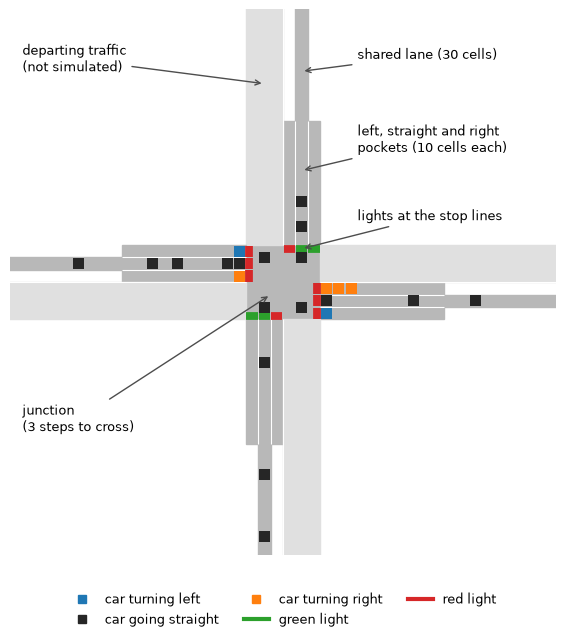

In [3]:
from utils.animation import IntersectionView, legend_handles

fig, ax = plt.subplots(figsize=(6, 6.4))
view = IntersectionView(ax, models[-1], "", extent=22)
view.info.set_visible(False)
fig.legend(handles=legend_handles(), loc="lower center", ncol=3, frameon=False, fontsize=9)
fig.tight_layout(rect=(0, 0.1, 1, 1))
view.fit_cars()
for xy, text_xy, note in [((1.5, 17), (6, 18), "shared lane (30 cells)"),
                          ((1.5, 9), (6, 10.5), "left, straight and right\npockets (10 cells each)"),
                          ((1.5, 2.7), (6, 5), "lights at the stop lines"),
                          ((-1, -1), (-21, -12), "junction\n(3 steps to cross)"),
                          ((-1.5, 16), (-21, 17), "departing traffic\n(not simulated)")]:
    ax.annotate(note, xy=xy, xytext=text_xy, fontsize=9, arrowprops=dict(arrowstyle="->", color="0.3"))
save(fig, "model")
plt.show()

**What to look for.** At the baseline, traffic is balanced and most cars go
straight. The untuned plan still gives each of the four phases 20 steps, so the
right-turn phases hold a green for the few cars turning right while straight-on
queues build up on red. Webster's plan gives the straight-and-left phases
longer greens (12 steps) than the right-turn phases (5 steps), but follows the
same cycle whatever is waiting. The adaptive controller switches often, in short
greens, to whichever phase's cars have waited longest, so its queues stay
shortest.

## 2. Baseline: the three controllers compared

Mean wait at the baseline, averaged over 30 seeds.

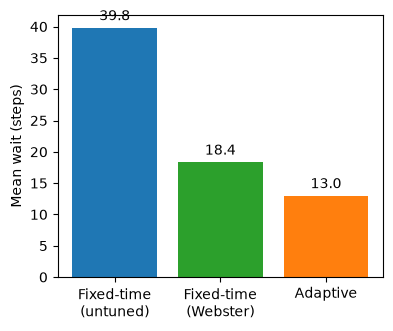

,mean wait (steps),cars served per 100 steps,fraction turned away,light changes per 100 steps
controller,,,,
Fixed-time (untuned),39.819,59.103,0.022,4.350
Fixed-time (Webster),18.354,58.763,0.022,8.700
Adaptive,13.000,58.773,0.022,12.408


In [4]:
base = fine[fine["sweep"] == "baseline"]
summary = base.groupby("controller")[["mean_wait", "throughput", "turned_away", "phase_changes"]].mean()

fig, ax = plt.subplots(figsize=(4.2, 3.4))
bars = ax.bar([LABELS[c].replace(" (", "\n(") for c in CONTROLLERS], summary.loc[CONTROLLERS, "mean_wait"],
              color=[COLOURS[c] for c in CONTROLLERS])
ax.bar_label(bars, fmt="%.1f", padding=3)
ax.set_ylabel("Mean wait (steps)")
save(fig, "baseline")
plt.show()

table = summary.loc[CONTROLLERS].rename(index=LABELS, columns={
    "mean_wait": "mean wait (steps)", "throughput": "cars served per 100 steps",
    "turned_away": "fraction turned away", "phase_changes": "light changes per 100 steps"})
table.round(3)

## 3. Mean wait as each setting changes

Each figure changes one setting and keeps the others at the baseline. Every
point is the mean of 10 seeds. The grey vertical
line marks the baseline value.

### Arrival rate

How busy the intersection is. The bottom panel shows the fraction of arriving
cars turned away because the entry was full: a controller that cannot keep up
fills its approach roads and starts turning cars away.

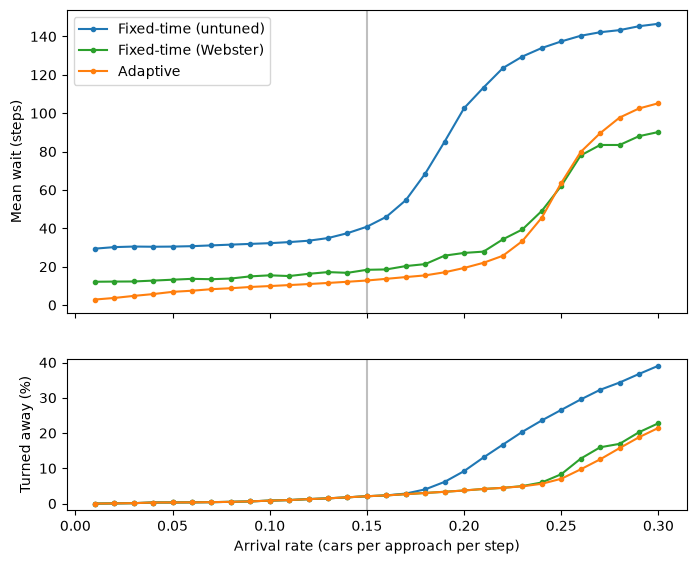

In [5]:
runs = fine[fine["sweep"] == "demand"]
fig, (top, bottom) = plt.subplots(2, 1, figsize=(8, 6.5), sharex=True, height_ratios=[2, 1])
plot_controllers(top, runs, "arrival_rate")
plot_controllers(bottom, runs, "arrival_rate", "turned_away", scale=100)
for ax in (top, bottom):
    ax.axvline(BASELINE["demand"], color="0.75", linewidth=1.5, zorder=0)
top.set_ylabel("Mean wait (steps)")
bottom.set_ylabel("Turned away (%)")
bottom.set_xlabel(FACTORS["demand"][1])
top.legend()
plt.show()

### North–south probability

The chance that an arriving car comes from the north or south: 0.5 is balanced, 1.0 means no traffic from the east or west.

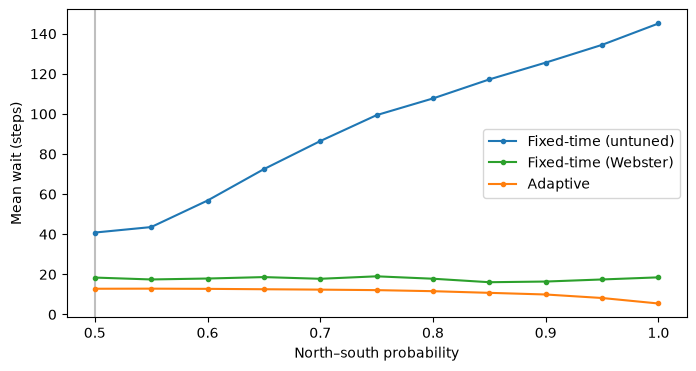

In [6]:
column, label = FACTORS["ns_probability"]
runs = fine[fine["sweep"] == "ns_probability"]
fig, ax = plt.subplots(figsize=(8, 4))
plot_controllers(ax, runs, column)
ax.axvline(BASELINE["ns_probability"], color="0.75", linewidth=1.5, zorder=0)
ax.set_xlabel(label)
ax.set_ylabel("Mean wait (steps)")
ax.legend()
plt.show()

### Fairness between directions

The same runs, with the mean wait of cars from the north and south (dark grey)
and from the east and west (red) shown separately, one panel per controller.
As traffic becomes one-sided, a controller can keep the overall average low by
favouring the busy direction while the few cars from the quiet direction wait
much longer. At 1.0 there are no east–west cars, so that line stops at 0.95.

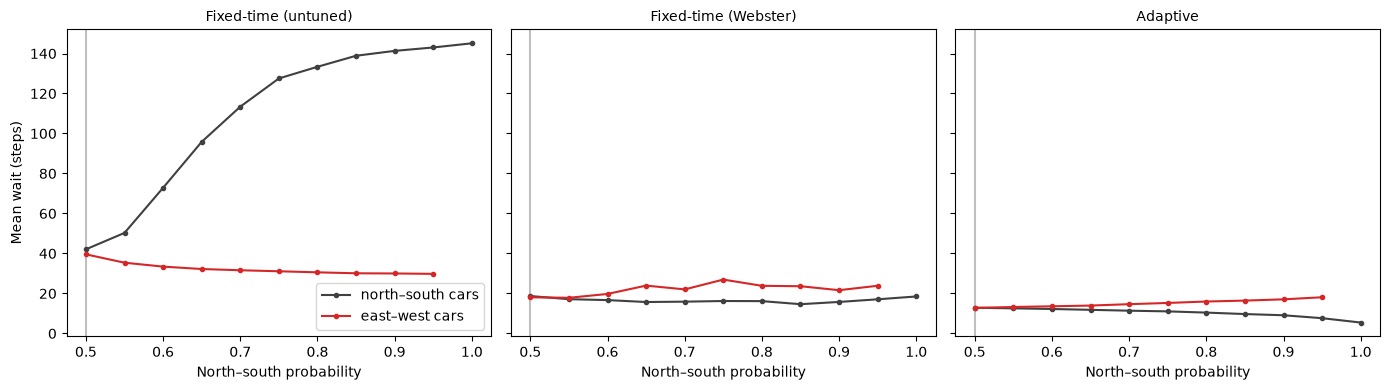

Mean wait (steps) of north-south (wait_ns) and east-west (wait_ew) cars
                        wait_ns wait_ew wait_ns wait_ew  wait_ns  wait_ew
controller                fixed   fixed webster webster adaptive adaptive
north_south_probability                                                  
0.50                       42.1    39.6    18.7    18.1     12.8     12.8
0.70                      113.4    31.6    15.9    22.0     11.4     14.6
0.90                      141.3    30.0    15.7    21.6      9.1     17.1
0.95                      143.0    29.8    17.1    23.8      7.6     18.1


In [7]:
runs = fine[fine["sweep"] == "ns_probability"]
fig, axes = plt.subplots(1, len(CONTROLLERS), figsize=(14, 4), sharey=True)
for ax, controller in zip(axes, CONTROLLERS):
    waits = runs[runs["controller"] == controller].groupby("north_south_probability")[["wait_ns", "wait_ew"]].mean()
    ax.plot(waits.index, waits["wait_ns"], marker="o", markersize=3, color="0.25", label="north–south cars")
    ax.plot(waits.index, waits["wait_ew"], marker="o", markersize=3, color="C3", label="east–west cars")
    ax.axvline(BASELINE["ns_probability"], color="0.75", linewidth=1.5, zorder=0)
    ax.set_title(LABELS[controller], fontsize=10)
    ax.set_xlabel(FACTORS["ns_probability"][1])
axes[0].set_ylabel("Mean wait (steps)")
axes[0].legend()
fig.tight_layout()
save(fig, "fairness")
plt.show()

table = runs.pivot_table(index="north_south_probability", columns="controller", values=["wait_ns", "wait_ew"])
print("Mean wait (steps) of north-south (wait_ns) and east-west (wait_ew) cars")
print(table.loc[[0.5, 0.7, 0.9, 0.95], [(v, c) for c in CONTROLLERS for v in ("wait_ns", "wait_ew")]].round(1))

### Reaction delay

The chance that a car starting from standstill stalls for a step. It slows the start of every queue.

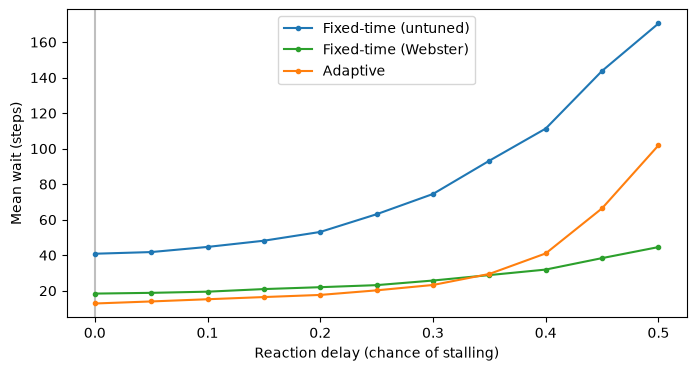

In [8]:
column, label = FACTORS["reaction_delay"]
runs = fine[fine["sweep"] == "reaction_delay"]
fig, ax = plt.subplots(figsize=(8, 4))
plot_controllers(ax, runs, column)
ax.axvline(BASELINE["reaction_delay"], color="0.75", linewidth=1.5, zorder=0)
ax.set_xlabel(label)
ax.set_ylabel("Mean wait (steps)")
ax.legend()
plt.show()

### Left-turn probability

The chance that a car turns left (right turns stay at 0.2; the rest go straight). Left turns get green together with straight-on cars.

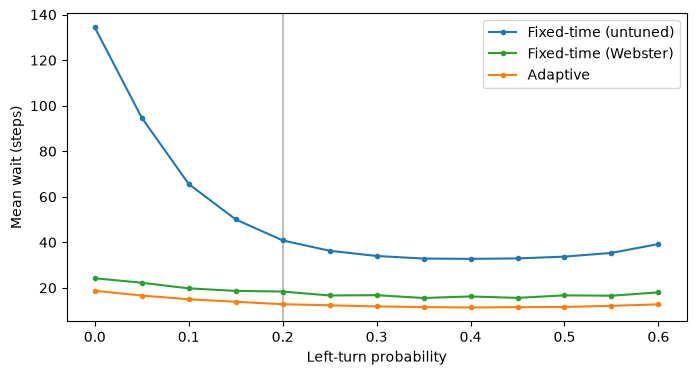

In [9]:
column, label = FACTORS["left_probability"]
runs = fine[fine["sweep"] == "left_probability"]
fig, ax = plt.subplots(figsize=(8, 4))
plot_controllers(ax, runs, column)
ax.axvline(BASELINE["left_probability"], color="0.75", linewidth=1.5, zorder=0)
ax.set_xlabel(label)
ax.set_ylabel("Mean wait (steps)")
ax.legend()
plt.show()

### Right-turn probability

The chance that a car turns right (left turns stay at 0.2; the rest go straight). Right turns cross oncoming traffic, so they get their own phase.

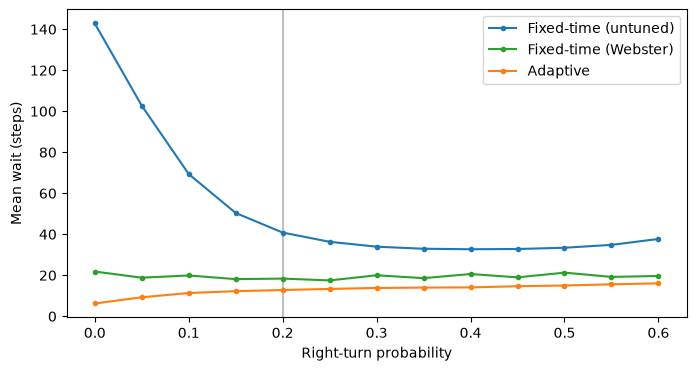

In [10]:
column, label = FACTORS["right_probability"]
runs = fine[fine["sweep"] == "right_probability"]
fig, ax = plt.subplots(figsize=(8, 4))
plot_controllers(ax, runs, column)
ax.axvline(BASELINE["right_probability"], color="0.75", linewidth=1.5, zorder=0)
ax.set_xlabel(label)
ax.set_ylabel("Mean wait (steps)")
ax.legend()
plt.show()

### All five settings in one figure

The five figures above side by side (with the fraction of cars turned away
against arrival rate), as used in the report.

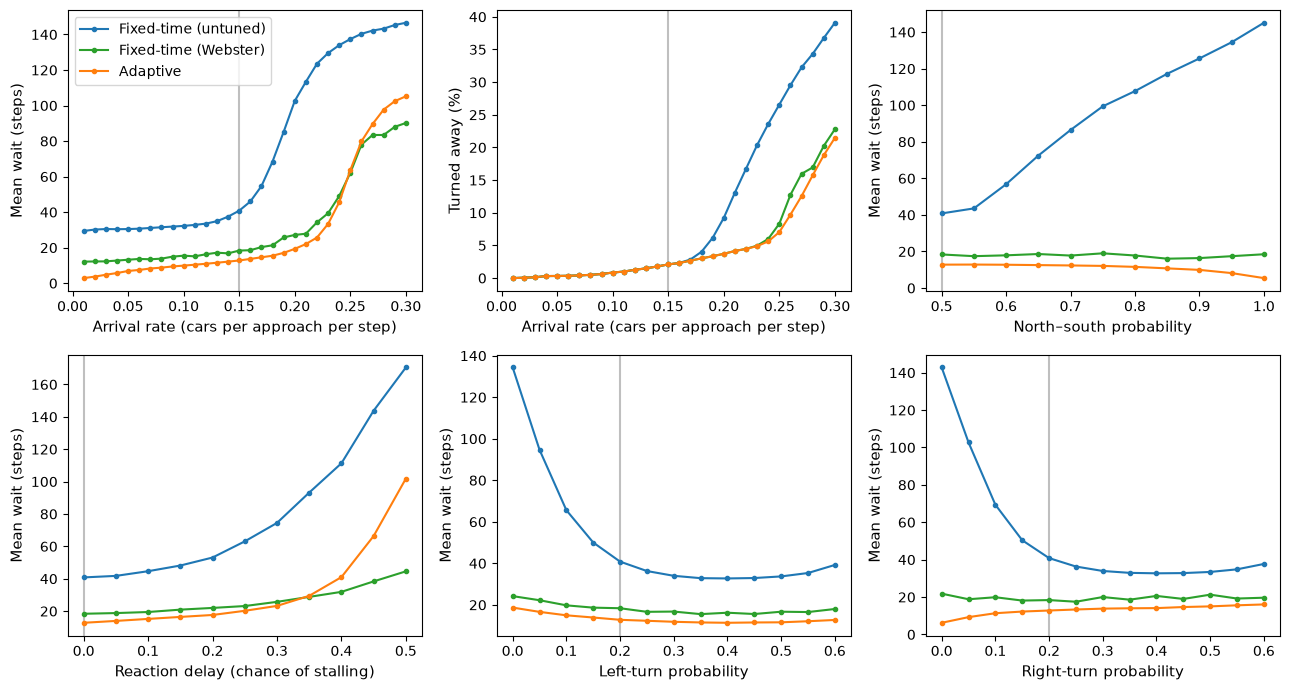

In [11]:
panels = [("demand", "mean_wait", "Mean wait (steps)", 1), ("demand", "turned_away", "Turned away (%)", 100),
          ("ns_probability", "mean_wait", "Mean wait (steps)", 1), ("reaction_delay", "mean_wait", "Mean wait (steps)", 1),
          ("left_probability", "mean_wait", "Mean wait (steps)", 1), ("right_probability", "mean_wait", "Mean wait (steps)", 1)]
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, (factor, value, ylabel, scale) in zip(axes.flat, panels):
    column, label = FACTORS[factor]
    plot_controllers(ax, fine[fine["sweep"] == factor], column, value, scale)
    ax.axvline(BASELINE[factor], color="0.75", linewidth=1.5, zorder=0)
    ax.set_xlabel(label, fontsize=11)
    ax.set_ylabel(ylabel, fontsize=11)
axes[0, 0].legend(fontsize=10)
fig.tight_layout()
save(fig, "wait_by_setting")
plt.show()

## 4. Several settings changed at once

Each scenario changes two or more settings from the baseline (each bar is
the mean of 10 seeds).

Settings of each scenario
                                arrival_rate  north_south_probability  \
scenario                                                                
baseline                                0.15                      0.5   
busy, one-sided                         0.18                      0.8   
busy, slow drivers                      0.18                      0.5   
one-sided, many right turns             0.15                      0.8   
slow drivers, many right turns          0.15                      0.5   
light, very one-sided                   0.08                      0.9   
all four harder                         0.18                      0.8   

                                right_turn_probability  reaction_delay  
scenario                                                                
baseline                                           0.2             0.0  
busy, one-sided                                    0.2             0.0  
busy, slow drivers      

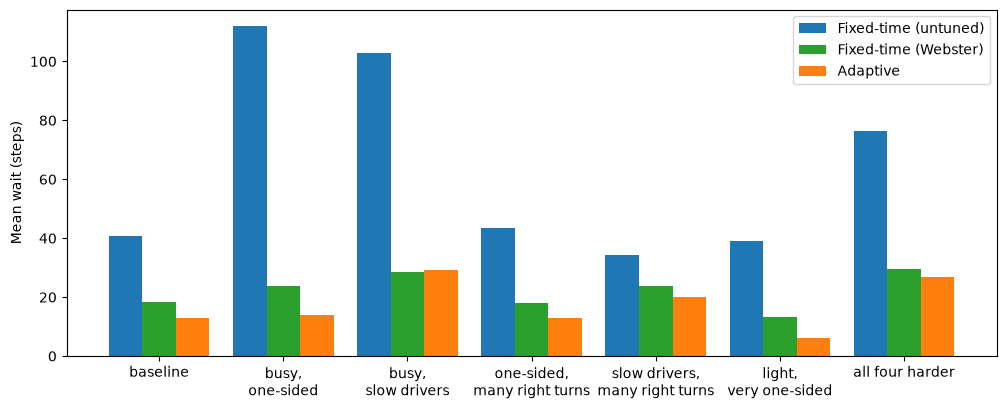

Mean wait (steps)
controller                      Fixed-time (untuned)  Fixed-time (Webster)  \
scenario                                                                     
baseline                                        40.8                  18.4   
busy, one-sided                                112.0                  23.8   
busy, slow drivers                             102.8                  28.6   
one-sided, many right turns                     43.4                  18.0   
slow drivers, many right turns                  34.3                  23.8   
light, very one-sided                           39.0                  13.2   
all four harder                                 76.5                  29.6   

controller                      Adaptive  
scenario                                  
baseline                            12.8  
busy, one-sided                     13.9  
busy, slow drivers                  29.2  
one-sided, many right turns         12.9  
slow drivers, many ri

In [12]:
scenarios = load("scenarios.csv")
order = list(dict.fromkeys(scenarios["scenario"]))
means = scenarios.pivot_table(index="scenario", columns="controller", values="mean_wait").loc[order]

settings = (scenarios.drop_duplicates("scenario").set_index("scenario").loc[order,
            ["arrival_rate", "north_south_probability", "right_turn_probability", "reaction_delay"]])
print("Settings of each scenario")
print(settings)

fig, ax = plt.subplots(figsize=(12, 4.5))
x = np.arange(len(order))
width = 0.27
for i, controller in enumerate(CONTROLLERS):
    ax.bar(x + (i - 1) * width, means[controller], width, color=COLOURS[controller], label=LABELS[controller])
ax.set_xticks(x, [name.replace(", ", ",\n") for name in order])
ax.set_ylabel("Mean wait (steps)")
ax.legend()
save(fig, "scenarios")
plt.show()

print("Mean wait (steps)")
print(means[CONTROLLERS].rename(columns=LABELS).round(1))

The main experiment (`data/sweep_results.csv`) changes four settings together
in every combination. Below: adaptive control's reduction in mean wait
against Webster's plan, by arrival rate and north–south probability, for each
reaction delay (averaged over right-turn probabilities and seeds; positive
means adaptive waits less).

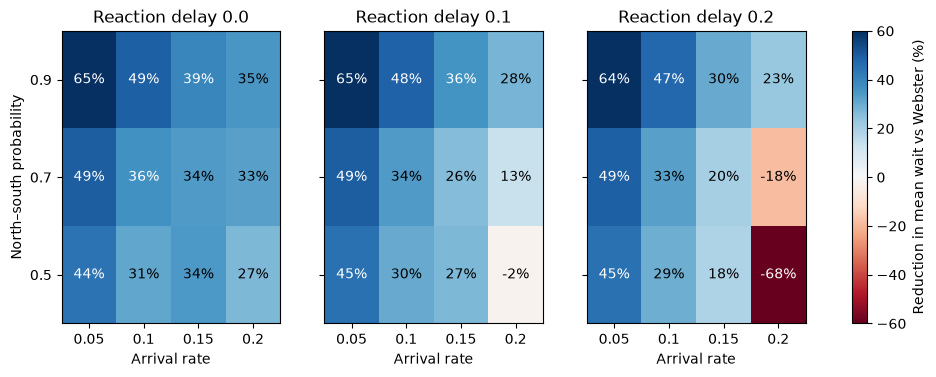

Over all 1080 paired situations, adaptive waits less than Webster's plan in 93.1% and less than the untuned plan in 98.9%.
Adaptive's reduction in mean wait vs Webster (%), averaged over all other settings
arrival_rate             0.05    52.8
                         0.10    37.5
                         0.15    29.5
                         0.20     7.8
north_south_probability  0.50    21.8
                         0.70    29.9
                         0.90    44.0
right_turn_probability   0.10    41.2
                         0.30    29.8
                         0.50    24.7
reaction_delay           0.00    39.7
                         0.10    33.2
                         0.20    22.7
Name: vs_webster, dtype: float64


In [13]:
main = load("sweep_results.csv")
wide = main.pivot_table(index=["arrival_rate", "north_south_probability", "right_turn_probability",
                               "reaction_delay", "seed"], columns="controller", values="mean_wait").reset_index()
wide["vs_webster"] = 100 * (wide["webster"] - wide["adaptive"]) / wide["webster"]
wide["vs_fixed"] = 100 * (wide["fixed"] - wide["adaptive"]) / wide["fixed"]
delays = sorted(wide["reaction_delay"].unique())
fig, axes = plt.subplots(1, len(delays), figsize=(12, 3.8), sharey=True)
for ax, delay in zip(axes, delays):
    table = wide[wide["reaction_delay"] == delay].pivot_table(
        index="north_south_probability", columns="arrival_rate", values="vs_webster")
    image = ax.imshow(table.values, cmap="RdBu", vmin=-60, vmax=60, origin="lower", aspect="auto")
    for i in range(table.shape[0]):
        for j in range(table.shape[1]):
            value = table.values[i, j]
            ax.text(j, i, f"{value:.0f}%", ha="center", va="center", color="white" if abs(value) > 35 else "black")
    ax.set_xticks(range(table.shape[1]), table.columns)
    ax.set_yticks(range(table.shape[0]), table.index)
    ax.set_xlabel("Arrival rate")
    ax.set_title(f"Reaction delay {delay}")
axes[0].set_ylabel("North–south probability")
fig.colorbar(image, ax=axes, label="Reduction in mean wait vs Webster (%)")
save(fig, "heatmap")
plt.show()

print(f"Over all {len(wide)} paired situations, adaptive waits less than Webster's plan in "
      f"{100 * (wide['vs_webster'] > 0).mean():.1f}% and less than the untuned plan in "
      f"{100 * (wide['vs_fixed'] > 0).mean():.1f}%.")
effects = pd.concat({column: wide.groupby(column)["vs_webster"].mean()
                     for column in ["arrival_rate", "north_south_probability", "right_turn_probability", "reaction_delay"]})
print("Adaptive's reduction in mean wait vs Webster (%), averaged over all other settings")
print(effects.round(1))

## 5. Effect of each setting on the adaptive advantage

Adaptive control's reduction in mean wait against Webster's plan (green) and
against the untuned plan (blue), as each setting changes from the baseline
(paired run by run and averaged over 10 seeds). Above zero, adaptive waits less.
Each panel has its own vertical scale.

The zigzag in the turning panels comes from the cellular automaton itself. A
queue starts off one car every two steps, so a green of g steps lets through
about g/2 cars, rounded up: a 9-step green serves as many cars as a 10-step
one. As the turning probability rises, Webster's plan moves one step of green
at a time between phases (for right turns: 11 and 5 steps, then 10 and 6, 9
and 7, ...), alternating between greens that use their time fully and greens
that waste a step, and its waits rise and fall with them.

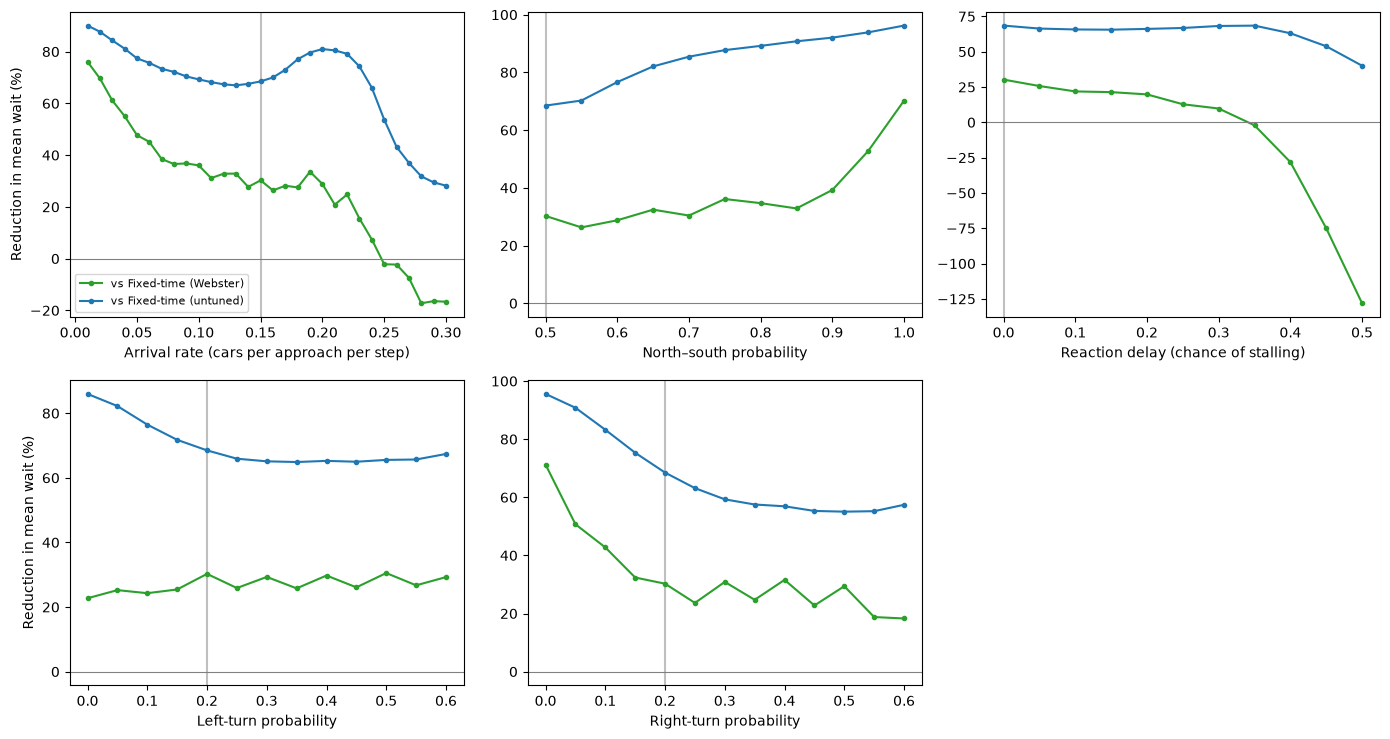

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
for ax, (factor, (column, label)) in zip(axes.flat, FACTORS.items()):
    runs = fine[fine["sweep"] == factor]
    for against in ["webster", "fixed"]:
        mean = advantage(runs, column, against)
        ax.plot(mean.index, mean, marker="o", markersize=3, color=COLOURS[against],
                label=f"vs {LABELS[against]}")
    ax.axhline(0, color="grey", linewidth=0.8)
    ax.axvline(BASELINE[factor], color="0.75", linewidth=1.5, zorder=0)
    ax.set_xlabel(label)
for ax in axes[:, 0]:
    ax.set_ylabel("Reduction in mean wait (%)")
axes[0, 0].legend(fontsize=8)
axes.flat[-1].axis("off")
fig.tight_layout()
save(fig, "effect_of_each_setting")
plt.show()

## 6. The lights and the cars waiting

One run of each controller at the baseline (seed 0), recorded step by step:
the cars waiting in the north–south and east–west pockets during 300 steps
of the measured window. Shading shows which direction has a green light;
white is all-red, between two greens.

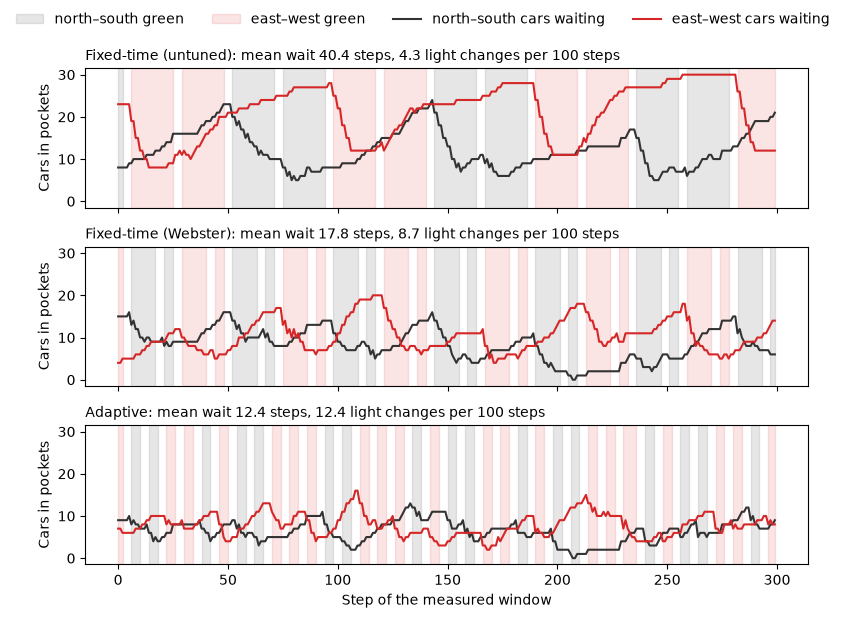

In [15]:
steps = 300
fig, axes = plt.subplots(len(CONTROLLERS), 1, figsize=(8, 6.2), sharex=True, sharey=True)
for ax, controller in zip(axes, CONTROLLERS):
    run = run_and_measure(Intersection(controller=controller, **BASELINE, seed=0), record=True)
    queues = run["queues"][:steps]          # steps x approaches (N, E, S, W) x moves
    phases = run["phases"][:steps]          # 0, 1 = north-south green; 2, 3 = east-west green; -1 = all-red
    t = np.arange(steps)
    ax.fill_between(t, 0, 1, where=np.isin(phases, [0, 1]), color="0.35", alpha=0.15,
                    transform=ax.get_xaxis_transform(), step="mid", label="north–south green")
    ax.fill_between(t, 0, 1, where=np.isin(phases, [2, 3]), color="C3", alpha=0.12,
                    transform=ax.get_xaxis_transform(), step="mid", label="east–west green")
    ax.plot(t, queues[:, [0, 2]].sum(axis=(1, 2)), color="0.2", label="north–south cars waiting")
    ax.plot(t, queues[:, [1, 3]].sum(axis=(1, 2)), color="C3", label="east–west cars waiting")
    ax.set_title(f"{LABELS[controller]}: mean wait {run['mean_wait']:.1f} steps, "
                 f"{run['phase_changes']:.1f} light changes per 100 steps", loc="left", fontsize=10)
    ax.set_ylabel("Cars in pockets")
axes[-1].set_xlabel("Step of the measured window")
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.legend(*axes[0].get_legend_handles_labels(), ncol=4, loc="upper center", frameon=False)
save(fig, "lights_and_queues")
plt.show()

## 7. Pocket lengths

Each approach is a shared lane that splits into three pockets. If a pocket is
full, the car at the split waits, and so does everyone behind it, wherever
they are going (spillback). Left: mean wait against the length of the two
turning pockets, with 20% and 40% of cars turning right (one colour each per
controller; see the legend).
Middle: how often a car at the split was blocked by its full pocket.
Right: mean wait against the length of the straight pocket (turning pockets
10 cells). The main experiment uses 10 cells for every pocket.

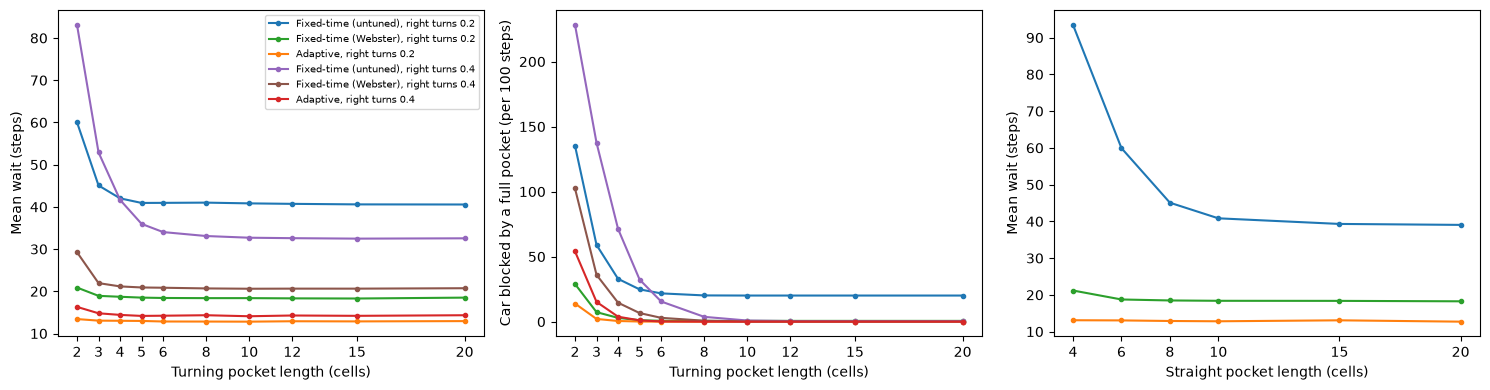

In [16]:
pockets = load("fine_pockets.csv")
turning = pockets[pockets["sweep"] == "turn_pocket_length"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for right, colours in [(0.2, COLOURS), (0.4, ALT_COLOURS)]:
    runs = turning[turning["right_turn_probability"] == right]
    for ax, value in zip(axes[:2], ["mean_wait", "full_pocket_blocks"]):
        for controller in CONTROLLERS:
            mean = runs[runs["controller"] == controller].groupby("turn_pocket_length")[value].mean()
            ax.plot(mean.index, mean, marker="o", markersize=3, color=colours[controller],
                    label=f"{LABELS[controller]}, right turns {right}")
plot_controllers(axes[2], pockets[pockets["sweep"] == "pocket_length"], "straight_pocket_length")
axes[0].set_ylabel("Mean wait (steps)")
axes[1].set_ylabel("Car blocked by a full pocket (per 100 steps)")
axes[2].set_ylabel("Mean wait (steps)")
for ax in axes[:2]:
    ax.set_xticks(sorted(turning["turn_pocket_length"].unique()))
    ax.set_xlabel("Turning pocket length (cells)")
axes[2].set_xticks(sorted(pockets.loc[pockets["sweep"] == "pocket_length", "straight_pocket_length"].unique()))
axes[2].set_xlabel("Straight pocket length (cells)")
axes[0].legend(fontsize=7)
fig.tight_layout()
save(fig, "pocket_lengths")
plt.show()

## 8. Keeping blocked cars in a queue

Everywhere above, a car that finds the first cell of its road occupied is
turned away and never counted again, which caps how long anyone can wait. Here
the baseline and the one-setting sweeps are repeated with such cars waiting in
a queue off the map instead (`queue_blocked_arrivals=True`,
`data/fine_sweeps_queued.csv`), so no car is lost and the time spent in that
queue counts as waiting. Blue, green and orange: blocked cars queue; purple,
brown and red: blocked cars turned away (the results above). Waits are on a
log scale. The last panel shows how many cars, on average, are waiting off the
map: once a controller cannot keep up, this queue grows for the whole run.

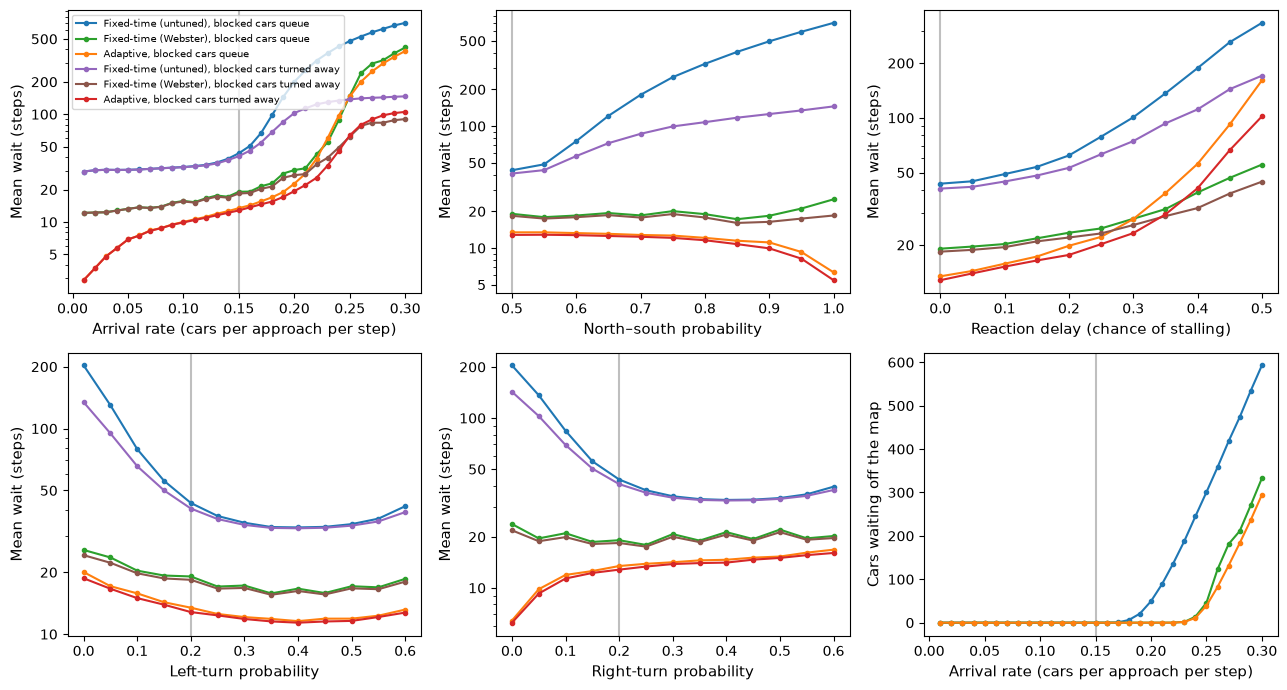

Baseline mean wait (steps)
            queue  turned away
controller                    
fixed        42.3         39.8
webster      19.0         18.4
adaptive     13.5         13.0

Mean wait (steps) against arrival rate
              queue                  turned away                 
controller    fixed webster adaptive       fixed webster adaptive
arrival_rate                                                     
0.15           43.5    19.1     13.4        40.8    18.4     12.8
0.20          200.0    30.3     22.7       102.6    27.2     19.3
0.22          314.6    42.4     38.5       123.5    34.3     25.7
0.25          477.4   148.1    146.2       137.4    62.1     63.7
0.30          705.0   416.6    386.4       146.6    90.2    105.2

Mean wait (steps) against reaction delay
                queue                  turned away                 
controller      fixed webster adaptive       fixed webster adaptive
reaction_delay                                                     
0.2 

In [17]:
from matplotlib.ticker import FormatStrFormatter, LogLocator, NullFormatter

queued = load("fine_sweeps_queued.csv")
panels = [("demand", "mean_wait"), ("ns_probability", "mean_wait"), ("reaction_delay", "mean_wait"),
          ("left_probability", "mean_wait"), ("right_probability", "mean_wait"), ("demand", "queue_outside")]
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, (factor, value) in zip(axes.flat, panels):
    column, label = FACTORS[factor]
    modes = [(queued, COLOURS, "queue")] + ([(fine, ALT_COLOURS, "turned away")] if value == "mean_wait" else [])
    for data, colours, how in modes:
        runs = data[data["sweep"] == factor]
        for controller in CONTROLLERS:
            mean = runs[runs["controller"] == controller].groupby(column)[value].mean()
            ax.plot(mean.index, mean, marker="o", markersize=3, color=colours[controller],
                    label=f"{LABELS[controller]}, blocked cars {how}")
    ax.axvline(BASELINE[factor], color="0.75", linewidth=1.5, zorder=0)
    ax.set_xlabel(label, fontsize=11)
    if value == "mean_wait":
        ax.set_yscale("log")
        ax.yaxis.set_major_locator(LogLocator(base=10, subs=(1, 2, 5)))   # ticks at 1, 2, 5, 10, 20, 50, ...
        ax.yaxis.set_major_formatter(FormatStrFormatter("%g"))
        ax.yaxis.set_minor_formatter(NullFormatter())
        ax.set_ylabel("Mean wait (steps)", fontsize=11)
    else:
        ax.set_ylabel("Cars waiting off the map", fontsize=11)
axes[0, 0].legend(fontsize=7)
fig.tight_layout()
save(fig, "queued")
plt.show()


def waits(data, factor, values):
    # Mean wait of each controller at the chosen values of one setting.
    column = FACTORS[factor][0]
    runs = data[(data["sweep"] == factor) & data[column].isin(values)]
    return runs.pivot_table(index=column, columns="controller", values="mean_wait")[CONTROLLERS]


both = lambda factor, values: pd.concat({"queue": waits(queued, factor, values),
                                         "turned away": waits(fine, factor, values)}, axis=1).round(1)
baseline = pd.DataFrame({"queue": queued[queued["sweep"] == "baseline"].groupby("controller")["mean_wait"].mean(),
                         "turned away": base.groupby("controller")["mean_wait"].mean()}).loc[CONTROLLERS]
print("Baseline mean wait (steps)")
print(baseline.round(1))
print("\nMean wait (steps) against arrival rate")
print(both("demand", [0.15, 0.2, 0.22, 0.25, 0.3]))
print("\nMean wait (steps) against reaction delay")
print(both("reaction_delay", [0.2, 0.3, 0.4, 0.5]))
served = queued[queued["sweep"] == "demand"].assign(served=lambda d: d["throughput"] / (400 * d["arrival_rate"]))
print("\nFraction of arriving cars served when they queue, against arrival rate")
print(served.pivot_table(index="arrival_rate", columns="controller", values="served")
      .loc[[0.2, 0.22, 0.24, 0.26, 0.28, 0.3], CONTROLLERS].round(2))